# HT-9046MX — Visual Analysis Story

Notebook สำหรับ Google Colab ที่รวมผลวิเคราะห์ HT-9046MX ไว้ในจุดเดียว เพื่อให้ตอบได้ชัดเจนว่า

- มีข้อมูลเครื่องไหนมากน้อยเพียงใด และข้อมูลส่วนใดใช้สร้าง baseline ได้
- baseline ของแต่ละเครื่อง / module / `SV` เท่ากันหรือไม่
- pressure, valve และ temperature สัมพันธ์กันอย่างไรในแต่ละเครื่องและแต่ละ module
- relative features ช่วยลดความต่างระหว่างเครื่องอย่างไร
- temporal validation, leave-one-machine-out และ external test ให้ผลอย่างไร

**ขอบเขตการตีความตาม `README_System.md`**

1. เปรียบเทียบภายใน module และ state เดียวกันก่อนเสมอ
2. แยก `SV=ON` และ `SV=OFF`; ไม่อนุมานว่า `SV=ON` คือ Room หรือ Hot
3. ตัด `MValveHome`, negative valve command, global stop และ control transient ออกจาก normal baseline
4. correlation แสดงความสัมพันธ์ ไม่ได้ยืนยันเหตุและผล
5. anomaly คือ “ต่างจากพฤติกรรมอ้างอิง” ไม่ใช่คำยืนยัน leak หรือ failure

> Notebook นี้อ่านผลที่คำนวณจากข้อมูลจริงใน `notebooks/outputs/` และใช้ minute cache สำหรับ drill-down จึงเปิดเร็วกว่าเริ่มสแกน Parquet ดิบ 26 ล้านแถวใหม่ทุกครั้ง

## 1. Setup

บน Colab ให้วางทั้งโฟลเดอร์โปรเจกต์ `OPERATION_P` ไว้ใน Google Drive แล้วตั้ง `PROJECT_ROOT_OVERRIDE` หากระบบหาโฟลเดอร์ไม่พบ สามารถเปิด `MOUNT_GOOGLE_DRIVE = True` เพื่อ mount Drive จาก notebook ได้

In [1]:
import importlib.util
import json
import sys
import subprocess
from pathlib import Path

required = {
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "polars": "polars",
    "pyarrow": "pyarrow",
    "ipywidgets": "ipywidgets",
}
missing = [pip_name for module, pip_name in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import HTML, Markdown, display

try:
    import ipywidgets as widgets
except Exception:
    widgets = None

MOUNT_GOOGLE_DRIVE = False
PROJECT_ROOT_OVERRIDE = ""  # ตัวอย่าง: /content/drive/MyDrive/OPERATION_P

if "google.colab" in sys.modules and MOUNT_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

def find_project_root():
    candidates = []
    if PROJECT_ROOT_OVERRIDE:
        candidates.append(Path(PROJECT_ROOT_OVERRIDE))
    candidates += [
        Path.cwd(),
        Path.cwd().parent,
        Path("/content/OPERATION_P"),
        Path("/content/drive/MyDrive/OPERATION_P"),
    ]
    for candidate in candidates:
        candidate = candidate.expanduser().resolve()
        if (candidate / "README_System.md").exists():
            return candidate
    raise FileNotFoundError(
        "ไม่พบ README_System.md — กรุณาตั้ง PROJECT_ROOT_OVERRIDE ให้ชี้ไปยังโฟลเดอร์ OPERATION_P"
    )

PROJECT_ROOT = find_project_root()
BASE_OUT = PROJECT_ROOT / "notebooks" / "outputs" / "ht9046mx_colab_analysis"
ML_OUT = PROJECT_ROOT / "notebooks" / "outputs" / "ht9046mx_ml_calibration"
FIG_OUT = PROJECT_ROOT / "notebooks" / "outputs" / "ht9046mx_visual_story" / "figures"
FIG_OUT.mkdir(parents=True, exist_ok=True)

required_artifacts = [
    BASE_OUT / "analysis_summary.json",
    BASE_OUT / "baseline_stats.csv",
    BASE_OUT / "spearman_correlations.csv",
    BASE_OUT / "cache" / "minute_module_state.parquet",
    ML_OUT / "ml_validation_summary.json",
    ML_OUT / "temporal_validation.csv",
    ML_OUT / "lomo_validation.csv",
    ML_OUT / "external_test_results.csv",
]
missing_artifacts = [str(p) for p in required_artifacts if not p.exists()]
if missing_artifacts:
    raise FileNotFoundError(
        "ผลวิเคราะห์ที่ต้องใช้ยังไม่ครบ กรุณารัน HT9046MX_State_Aware_Baseline_Analysis.ipynb "
        "และ HT9046MX_ML_Calibration_LOMO.ipynb ก่อน\n" + "\n".join(missing_artifacts)
    )

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 160,
    "axes.titleweight": "bold",
    "axes.labelcolor": "#243447",
    "text.color": "#243447",
    "font.size": 10,
})

PALETTE = {
    "blue": "#2F6BFF",
    "gold": "#D79A24",
    "orange": "#E97932",
    "olive": "#7D8E45",
    "pink": "#C85D8E",
    "ink": "#243447",
    "light": "#DCE6F2",
    "grey": "#8796A5",
}

def savefig(name):
    path = FIG_OUT / name
    plt.savefig(path, bbox_inches="tight", facecolor="white")
    return path

print(f"Project root: {PROJECT_ROOT}")
print(f"Figures: {FIG_OUT}")

Project root: C:\Users\Book\OneDrive\Documents\ChatGPT\OPERATION_P
Figures: C:\Users\Book\OneDrive\Documents\ChatGPT\OPERATION_P\notebooks\outputs\ht9046mx_visual_story\figures


## 2. Load reviewed analysis artifacts

In [2]:
with open(BASE_OUT / "analysis_summary.json", encoding="utf-8") as f:
    analysis_summary = json.load(f)
with open(ML_OUT / "ml_validation_summary.json", encoding="utf-8") as f:
    ml_summary = json.load(f)

def read_csv(name, root=BASE_OUT):
    return pd.read_csv(root / name, dtype={"machine_number": "string"})

inventory = read_csv("machine_inventory.csv")
state_counts = read_csv("state_counts.csv")
coverage = read_csv("module_coverage.csv")
readiness = read_csv("machine_ml_readiness.csv")
baseline = read_csv("baseline_stats.csv")
comparability = read_csv("baseline_comparability.csv")
correlations = read_csv("spearman_correlations.csv")
lag_relationships = read_csv("lag_relationships.csv")
best_lags = read_csv("best_lag_relationships.csv")
daily = read_csv("daily_baseline_trends.csv")

split_manifest = read_csv("machine_split_manifest.csv", ML_OUT)
temporal = read_csv("temporal_validation.csv", ML_OUT)
lomo = pd.read_csv(ML_OUT / "lomo_validation.csv", dtype={"held_out_machine": "string"})
external = read_csv("external_test_results.csv", ML_OUT)
portability = pd.read_csv(ML_OUT / "feature_portability.csv")

for frame in [inventory, state_counts, coverage, readiness, baseline, correlations, lag_relationships,
              best_lags, daily, split_manifest, temporal, external]:
    if "machine_number" in frame.columns:
        frame["machine_number"] = frame["machine_number"].astype("string").str.zfill(3)
lomo["held_out_machine"] = lomo["held_out_machine"].astype("string").str.zfill(3)
daily["date"] = pd.to_datetime(daily["date"])

minute = pl.read_parquet(BASE_OUT / "cache" / "minute_module_state.parquet").with_columns(
    pl.col("machine_number").cast(pl.Utf8).str.zfill(3),
    pl.col("minute").cast(pl.Datetime),
).sort(["machine_number", "module", "minute"])

control_states = ["ChangeValve", "MValveHome", "AdjustValve"]
minute = minute.with_columns(
    pl.when(pl.col("global_status") == "Stop")
    .then(pl.lit("GLOBAL_STOP"))
    .when(
        pl.col("module_status").is_in(control_states)
        | (pl.col("busy") == 1)
        | (pl.col("valve") < 0)
    )
    .then(pl.lit("CONTROL_SEQUENCE"))
    .when(pl.col("module_status") == "Off")
    .then(pl.lit("RUN_MODULE_OFF"))
    .when(
        (pl.col("global_status") == "Run")
        & (pl.col("module_status") == "On")
        & (pl.col("busy") == 0)
        & (pl.col("valve") >= 0)
        & (pl.col("sv") == "Off")
    )
    .then(pl.lit("RUN_ON_SV_OFF"))
    .when(
        (pl.col("global_status") == "Run")
        & (pl.col("module_status") == "On")
        & (pl.col("busy") == 0)
        & (pl.col("valve") >= 0)
        & (pl.col("sv") == "On")
    )
    .then(pl.lit("RUN_ON_SV_ON"))
    .otherwise(pl.lit("UNCLASSIFIED"))
    .alias("state")
)
minute = minute.with_columns(
    (
        (pl.col("state") != pl.col("state").shift(1).over(["machine_number", "module"]))
        | (pl.col("minute").diff().over(["machine_number", "module"]).dt.total_minutes() > 2)
    ).fill_null(True).alias("segment_start")
).with_columns(
    pl.col("segment_start").cast(pl.Int64).cum_sum().over(["machine_number", "module"]).alias("segment_id")
).with_columns(
    pl.col("minute").cum_count().over(["machine_number", "module", "segment_id"]).alias("minutes_in_state")
).with_columns(
    (
        pl.col("state").is_in(["RUN_ON_SV_OFF", "RUN_ON_SV_ON"])
        & (pl.col("minutes_in_state") >= 3)
    ).alias("baseline_eligible")
)

machines = sorted(inventory["machine_number"].astype(str).unique())
development_machines = ml_summary["development_machines"]
external_machines = ml_summary["external_test_machines"]
module_names = {
    1: "Index L Arm1", 2: "Index R Arm1", 3: "Index L Arm2", 4: "Index R Arm2",
    5: "SH1", 6: "SH2", 7: "Hot1", 8: "Hot2",
}

print(f"Loaded {len(machines)} machines and {minute.height:,} minute-module rows")

Loaded 19 machines and 3,548,928 minute-module rows


## 3. Executive overview — ทำอะไรไปแล้วบ้าง

กระบวนการที่ใช้จริง:

`26.16M raw rows` → `state qualification` → `3.55M minute-module rows` → `baseline by machine × module × SV` → `relative features` → `temporal + LOMO + external validation`

In [3]:
cards = [
    ("Parquet files", f"{analysis_summary['parquet_files']:,}"),
    ("Raw rows", f"{analysis_summary['raw_rows'] / 1e6:.2f}M"),
    ("Machines", f"{analysis_summary['machines']}"),
    ("Minute-module rows", f"{analysis_summary['minute_module_rows'] / 1e6:.2f}M"),
    ("Baseline eligible", f"{analysis_summary['baseline_eligible_rows'] / analysis_summary['minute_module_rows']:.1%}"),
    ("Calibration-ready machines", f"{ml_summary['development_machine_count']} / {analysis_summary['machines']}"),
]
html = "<div style='display:grid;grid-template-columns:repeat(3,minmax(180px,1fr));gap:12px'>"
for label, value in cards:
    html += (
        "<div style='padding:16px;border:1px solid #dce6f2;border-radius:12px;background:#fff'>"
        f"<div style='font-size:13px;color:#68788a'>{label}</div>"
        f"<div style='font-size:28px;font-weight:700;color:#243447'>{value}</div></div>"
    )
html += "</div>"
display(HTML(html))

display(Markdown(
    f"**ช่วงข้อมูล:** {analysis_summary['date_start'][:10]} ถึง {analysis_summary['date_end'][:10]}  "
    f"  \n**Development:** {', '.join(development_machines)}  "
    f"  \n**External test / shadow mode:** {', '.join(external_machines)}"
))

**ช่วงข้อมูล:** 2026-08-04 ถึง 2026-09-01    
**Development:** 017, 022, 024, 029, 041, 057, 058, 070, 072, 081, 082, 083    
**External test / shadow mode:** 056, 063, 071, 115, 118, 119, 124

## 4. Data coverage — เครื่องไหนมีข้อมูลพอสำหรับ calibration

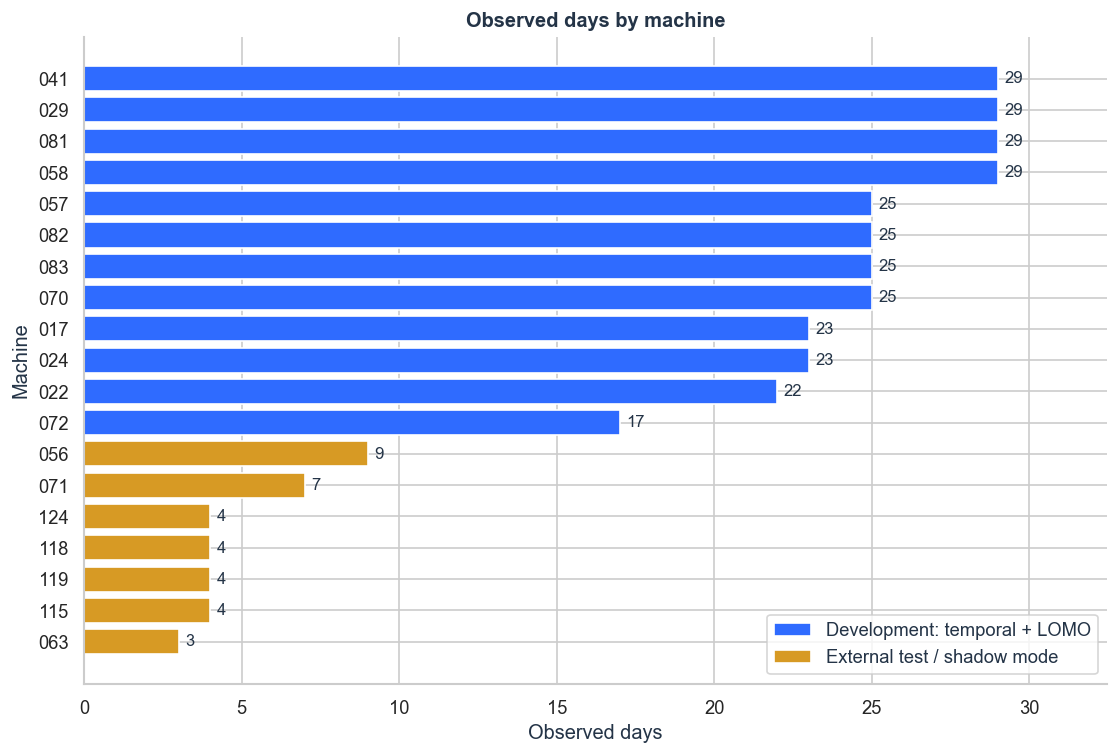

In [4]:
plot_inventory = inventory.merge(split_manifest, on="machine_number", how="left")
plot_inventory["role"] = plot_inventory["role"].fillna("external_test")
plot_inventory = plot_inventory.sort_values("observed_days", ascending=True)
colors = plot_inventory["role"].map({
    "development_temporal_lomo": PALETTE["blue"],
    "external_test": PALETTE["gold"],
}).fillna(PALETTE["gold"])

fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(plot_inventory["machine_number"], plot_inventory["observed_days"], color=colors)
ax.set_title("Observed days by machine")
ax.set_xlabel("Observed days")
ax.set_ylabel("Machine")
ax.set_xlim(0, max(plot_inventory["observed_days"]) * 1.12)
ax.bar_label(bars, padding=4, fmt="%.0f")
from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(facecolor=PALETTE["blue"], label="Development: temporal + LOMO"),
    Patch(facecolor=PALETTE["gold"], label="External test / shadow mode"),
], loc="lower right")
sns.despine()
savefig("01_machine_coverage.png")
plt.show()

**วิธีอ่าน:** สีน้ำเงินคือ 12 เครื่องที่มีอย่างน้อย 6 modules พร้อมสร้าง calibration profile ส่วนสีทองคือ 7 เครื่องที่มีข้อมูลน้อยหรือวันไม่พอ จึงกันไว้เป็น external test โดยไม่ใช้สร้าง profile หรือ train model

## 5. Operating states — ข้อมูลส่วนใดถูกใช้และถูกแยกออก

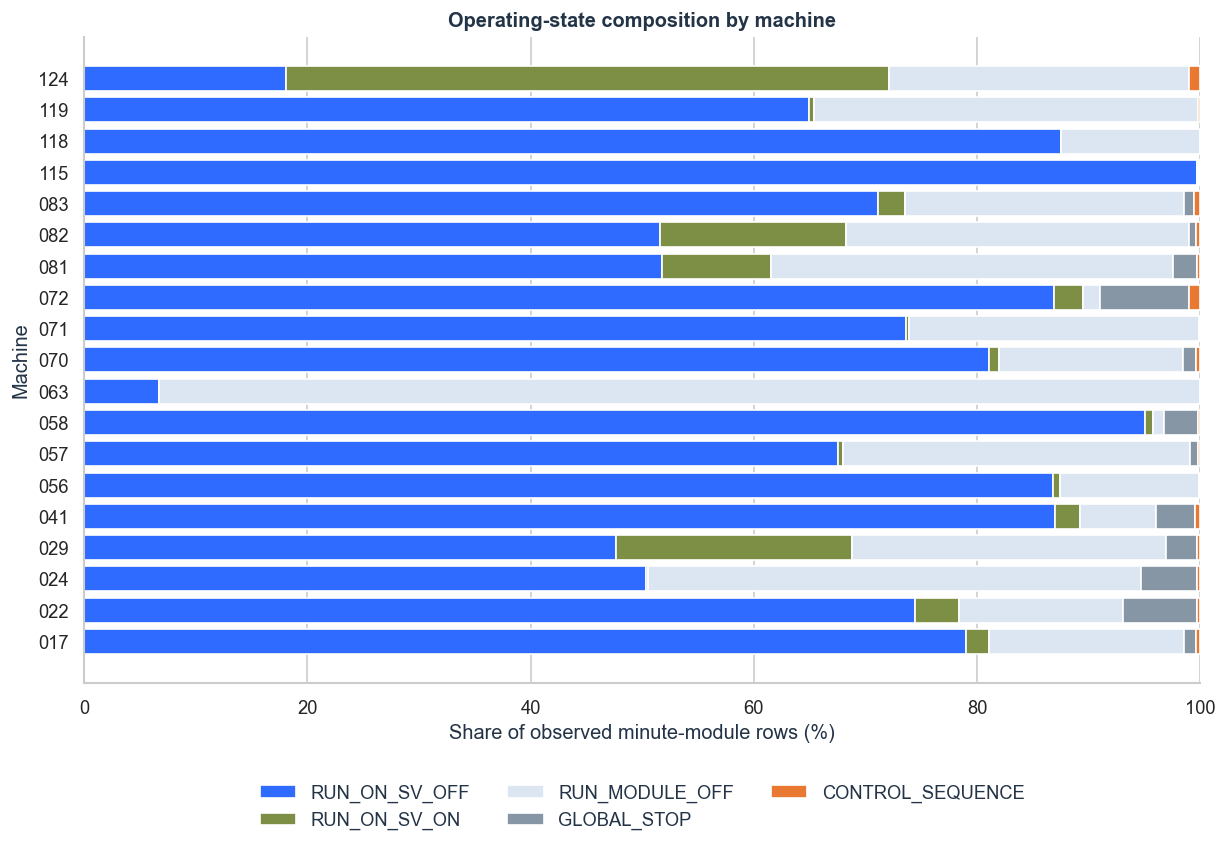

In [5]:
state_order = ["RUN_ON_SV_OFF", "RUN_ON_SV_ON", "RUN_MODULE_OFF", "GLOBAL_STOP", "CONTROL_SEQUENCE", "UNCLASSIFIED"]
state_palette = {
    "RUN_ON_SV_OFF": PALETTE["blue"],
    "RUN_ON_SV_ON": PALETTE["olive"],
    "RUN_MODULE_OFF": PALETTE["light"],
    "GLOBAL_STOP": PALETTE["grey"],
    "CONTROL_SEQUENCE": PALETTE["orange"],
    "UNCLASSIFIED": PALETTE["pink"],
}
machine_state = state_counts.groupby(["machine_number", "state"], as_index=False)["minutes"].sum()
machine_state["share"] = machine_state["minutes"] / machine_state.groupby("machine_number")["minutes"].transform("sum")
state_wide = machine_state.pivot(index="machine_number", columns="state", values="share").fillna(0)
state_wide = state_wide.reindex(columns=[s for s in state_order if s in state_wide.columns], fill_value=0)

fig, ax = plt.subplots(figsize=(12, 7))
left = np.zeros(len(state_wide))
y = np.arange(len(state_wide))
for state in state_wide.columns:
    values = state_wide[state].to_numpy() * 100
    ax.barh(y, values, left=left, label=state, color=state_palette[state])
    left += values
ax.set_yticks(y, state_wide.index)
ax.set_xlim(0, 100)
ax.set_xlabel("Share of observed minute-module rows (%)")
ax.set_ylabel("Machine")
ax.set_title("Operating-state composition by machine")
ax.legend(ncol=3, bbox_to_anchor=(0.5, -0.13), loc="upper center", frameon=False)
sns.despine()
savefig("02_state_composition.png")
plt.show()

Baseline ใช้เฉพาะ run state ที่เทียบเคียงได้และแยก SV ออกจากกัน ส่วน `GLOBAL_STOP`, `CONTROL_SEQUENCE`, `MValveHome`, negative valve และช่วง transient ไม่ถูกนำไปปนกับ normal cooling baseline

## 6. Baseline comparability — baseline ของทุกเครื่องเท่ากันหรือไม่

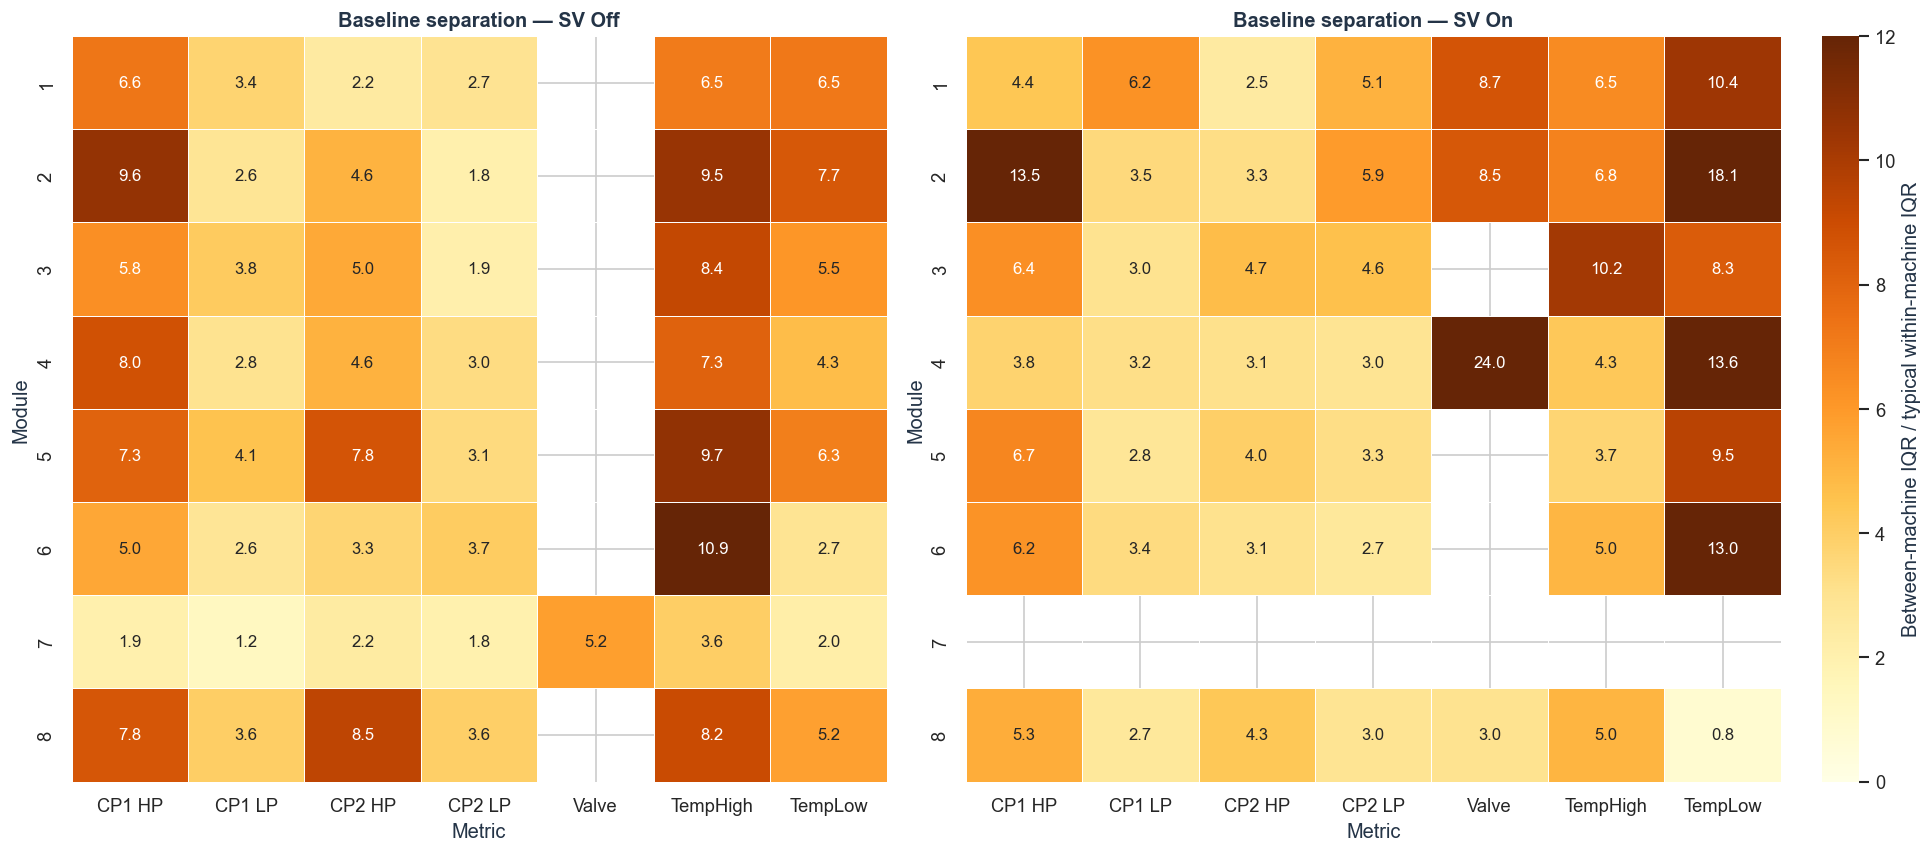

**คำตอบ:** baseline ไม่เท่ากัน — ค่ากลางของอัตราส่วนความต่างระหว่างเครื่องต่อความผันผวนภายในเครื่อง = **4.64 เท่า** และสูงสุด **24.0 เท่า** จึงควร calibrate แยก machine × module × SV

In [6]:
metric_labels = {
    "hp1": "CP1 HP", "lp1": "CP1 LP", "hp2": "CP2 HP", "lp2": "CP2 LP",
    "valve": "Valve", "temphi": "TempHigh", "templo": "TempLow",
}
fig, axes = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True)
for ax, sv in zip(axes, ["Off", "On"]):
    part = comparability[comparability["sv"] == sv].copy()
    heat = part.pivot(index="module", columns="metric", values="between_to_within_ratio")
    ordered_metrics = [m for m in metric_labels if m in heat.columns]
    heat = heat.reindex(index=range(1, 9), columns=ordered_metrics)
    heat.columns = [metric_labels[m] for m in heat.columns]
    sns.heatmap(
        heat, ax=ax, cmap="YlOrBr", vmin=0, vmax=min(12, np.nanmax(heat.values)),
        annot=True, fmt=".1f", linewidths=.5, cbar=ax is axes[-1],
        cbar_kws={"label": "Between-machine IQR / typical within-machine IQR"},
    )
    ax.set_title(f"Baseline separation — SV {sv}")
    ax.set_xlabel("Metric")
    ax.set_ylabel("Module")
savefig("03_baseline_comparability.png")
plt.show()

median_ratio = comparability["between_to_within_ratio"].median()
high_ratio = comparability["between_to_within_ratio"].max()
display(Markdown(
    f"**คำตอบ:** baseline ไม่เท่ากัน — ค่ากลางของอัตราส่วนความต่างระหว่างเครื่องต่อความผันผวนภายในเครื่อง = "
    f"**{median_ratio:.2f} เท่า** และสูงสุด **{high_ratio:.1f} เท่า** จึงควร calibrate แยก machine × module × SV"
))

## 7. Baseline map — ดูทุกเครื่องและทุก module

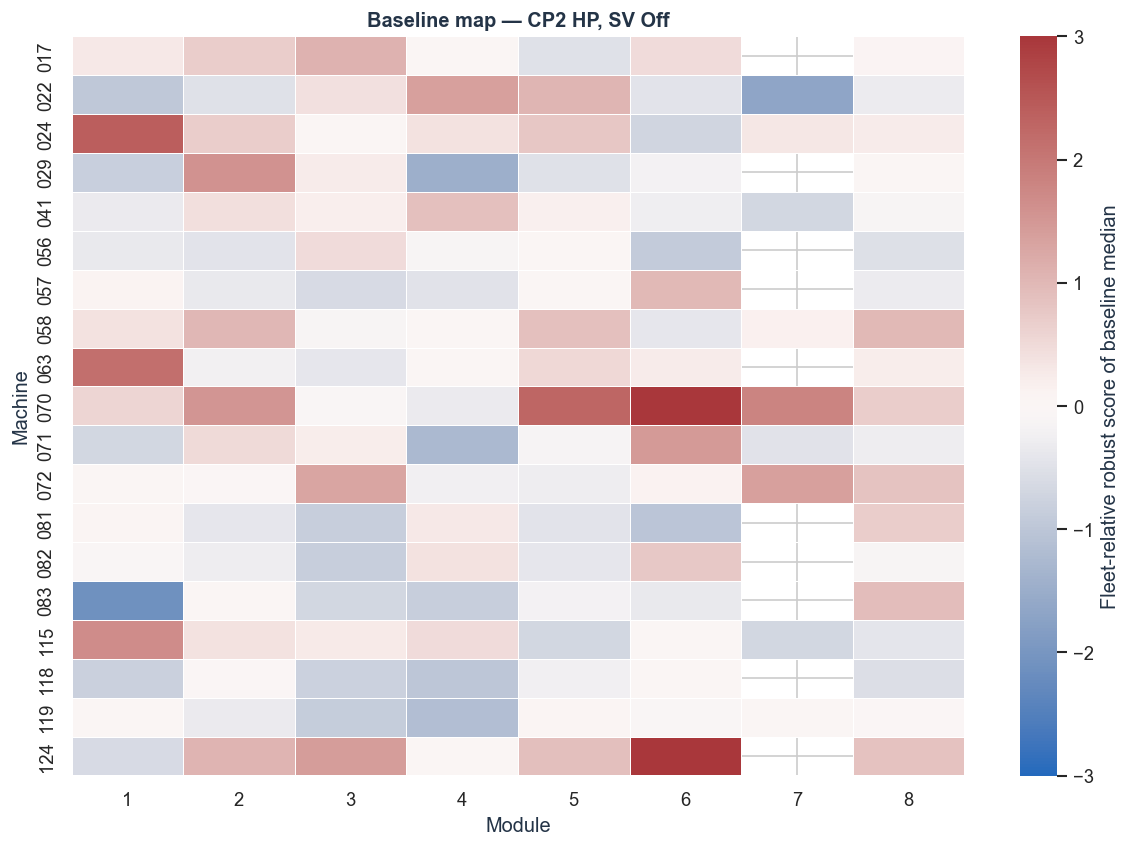

### Interactive baseline map

interactive(children=(Dropdown(description='Metric', index=2, options=('hp1', 'lp1', 'hp2', 'lp2', 'valve', 't…

In [7]:
def robust_center_scale(series):
    median = series.median()
    iqr = series.quantile(.75) - series.quantile(.25)
    scale = iqr if np.isfinite(iqr) and iqr > 1e-9 else 1.0
    return (series - median) / scale

def plot_baseline_map(metric="hp2", sv="Off", save=False):
    value_col = f"{metric}_median"
    part = baseline[(baseline["sv"] == sv) & baseline[value_col].notna()].copy()
    part["fleet_relative"] = part.groupby("module")[value_col].transform(robust_center_scale)
    heat = part.pivot(index="machine_number", columns="module", values="fleet_relative")
    heat = heat.reindex(index=machines, columns=range(1, 9))
    fig, ax = plt.subplots(figsize=(12, 8))
    sns.heatmap(
        heat, cmap="vlag", center=0, vmin=-3, vmax=3, linewidths=.35,
        cbar_kws={"label": "Fleet-relative robust score of baseline median"}, ax=ax,
    )
    ax.set_title(f"Baseline map — {metric_labels[metric]}, SV {sv}")
    ax.set_xlabel("Module")
    ax.set_ylabel("Machine")
    if save:
        savefig(f"04_baseline_map_{metric}_{sv.lower()}.png")
    plt.show()

plot_baseline_map("hp2", "Off", save=True)

if widgets is not None:
    display(Markdown("### Interactive baseline map"))
    widgets.interact(
        plot_baseline_map,
        metric=widgets.Dropdown(options=list(metric_labels), value="hp2", description="Metric"),
        sv=widgets.Dropdown(options=["Off", "On"], value="Off", description="SV"),
        save=widgets.fixed(False),
    )

สีใน heatmap เป็นตำแหน่งของ baseline เทียบกับเครื่องอื่นภายใน module เดียวกัน ไม่ใช่ health score สีเข้มจึงหมายถึง “ต่างจาก fleet” ไม่ได้หมายถึงเสีย

## 8. Baseline interval — ดูค่าจริงของเครื่องหนึ่งทีละ metric

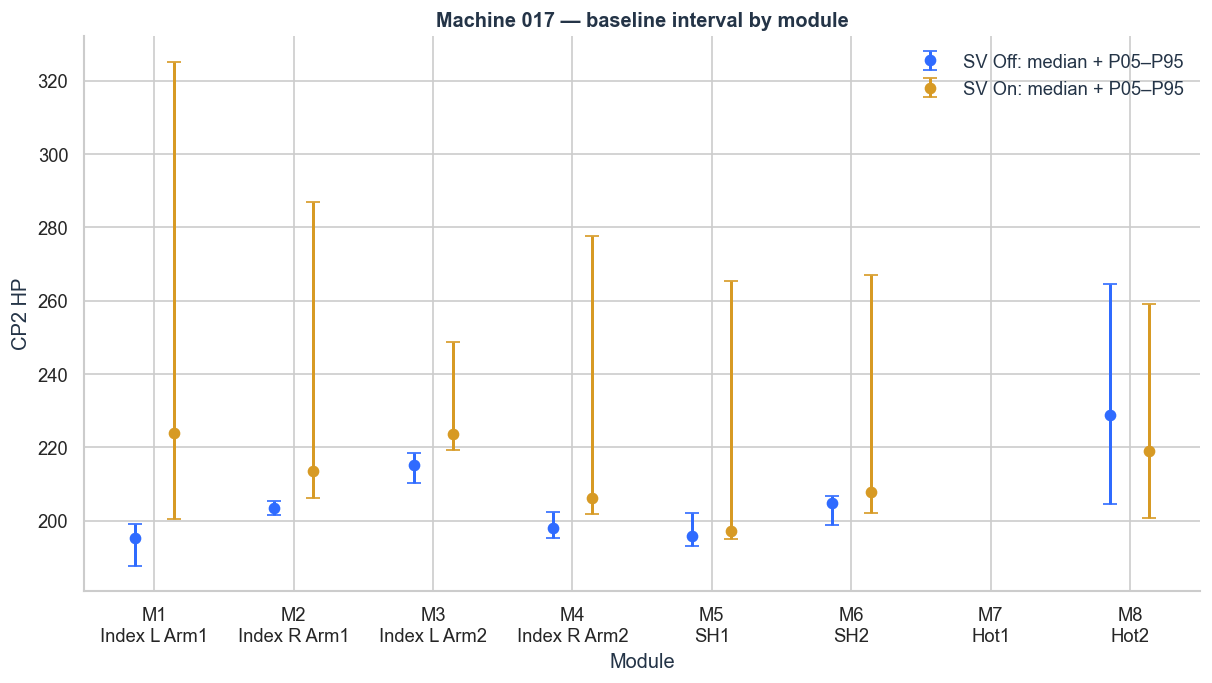

### Interactive machine baseline interval

interactive(children=(Dropdown(description='Machine', options=('017', '022', '024', '029', '041', '056', '057'…

In [8]:
def plot_machine_baseline(machine="017", metric="hp2", save=False):
    p = baseline[(baseline["machine_number"] == machine)].copy()
    med, lo, hi = f"{metric}_median", f"{metric}_q05", f"{metric}_q95"
    p = p.dropna(subset=[med]).sort_values(["module", "sv"])
    fig, ax = plt.subplots(figsize=(12, 6))
    sv_offsets = {"Off": -0.14, "On": 0.14}
    sv_colors = {"Off": PALETTE["blue"], "On": PALETTE["gold"]}
    for sv in ["Off", "On"]:
        q = p[p["sv"] == sv]
        if q.empty:
            continue
        x = q["module"].to_numpy() + sv_offsets[sv]
        y = q[med].to_numpy()
        yerr = np.vstack([y - q[lo].to_numpy(), q[hi].to_numpy() - y])
        ax.errorbar(x, y, yerr=yerr, fmt="o", capsize=4, lw=1.8, ms=6,
                    color=sv_colors[sv], label=f"SV {sv}: median + P05–P95")
    ax.set_xticks(range(1, 9), [f"M{i}\n{module_names[i]}" for i in range(1, 9)])
    ax.set_ylabel(metric_labels[metric])
    ax.set_xlabel("Module")
    ax.set_title(f"Machine {machine} — baseline interval by module")
    ax.legend(frameon=False)
    sns.despine()
    if save:
        savefig(f"05_machine_{machine}_{metric}_baseline_interval.png")
    plt.show()

plot_machine_baseline("017", "hp2", save=True)

if widgets is not None:
    display(Markdown("### Interactive machine baseline interval"))
    widgets.interact(
        plot_machine_baseline,
        machine=widgets.Dropdown(options=machines, value=machines[0], description="Machine"),
        metric=widgets.Dropdown(options=list(metric_labels), value="hp2", description="Metric"),
        save=widgets.fixed(False),
    )

## 8A. “ค่าปกติ” ต่างจาก “ความสัมพันธ์” อย่างไร

คำสองคำนี้ตอบคนละคำถาม:

- **Baseline level/range:** ค่านี้มักอยู่แถวไหนและแกว่งได้เท่าไร ภายใต้ `machine × module × SV × settled run state` เดียวกัน เช่น median, IQR และ P05–P95
- **Relationship:** เมื่อค่าหนึ่งเปลี่ยน ค่าอื่นมีแนวโน้มเปลี่ยนไปด้วยหรือไม่และไปทางใด เช่น Spearman correlation รวมถึง slope และ lag response

ดังนั้นสองเครื่องอาจมี pressure baseline ใกล้กันแต่ relationship ต่างกัน หรือ baseline ต่างกันแต่ relationship คล้ายกันก็ได้

> “ค่าปกติ” ใน notebook นี้หมายถึง **observed reference behavior ที่เกิดซ้ำบ่อยหลัง qualification ข้อมูล** ไม่ใช่คำยืนยันจากช่างว่าเครื่อง healthy 100%

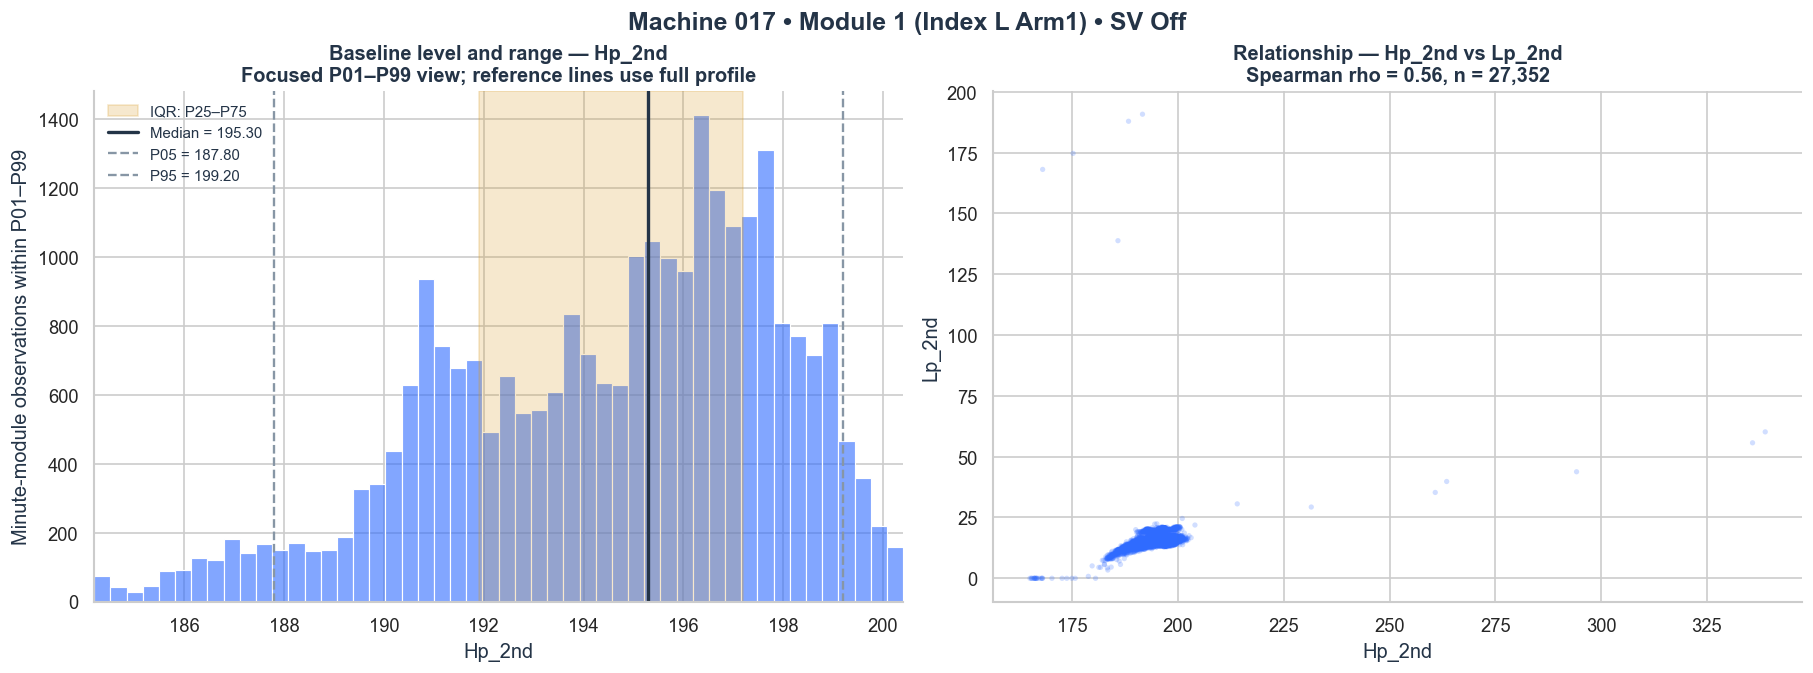

Meaning,Question answered,Result for selected profile
Observed baseline,Hp_2nd อยู่แถวไหนและกระจายเท่าไร,Median 195.30; IQR 191.90–197.20; P05–P95 187.80–199.20
Relationship,Hp_2nd กับ Lp_2nd เปลี่ยนร่วมกันแค่ไหน,Spearman rho 0.56; correlation is not causation


### Interactive: เลือกเครื่อง, module, SV และคู่ข้อมูล

interactive(children=(Dropdown(description='Machine', options=('017', '022', '024', '029', '041', '056', '057'…

In [9]:
relationship_features = ["hp1", "lp1", "hp2", "lp2", "valve", "temphi", "templo"]
relationship_labels = {
    "hp1": "Hp_1st", "lp1": "Lp_1st", "hp2": "Hp_2nd", "lp2": "Lp_2nd",
    "valve": "Valve", "temphi": "TempHigh", "templo": "TempLow",
}

def explain_normal_and_relationship(
    machine="017", module=1, sv="Off", feature_x="hp2", feature_y="lp2", save=False
):
    profile = (
        minute.filter(
            (pl.col("machine_number") == machine)
            & (pl.col("module") == int(module))
            & pl.col("baseline_eligible")
            & (pl.col("sv") == sv)
        )
        .select(relationship_features)
        .to_pandas()
        .dropna(subset=[feature_x, feature_y])
    )
    if len(profile) < 50:
        display(Markdown(
            f"ข้อมูลไม่พอสำหรับ Machine {machine}, Module {module}, SV {sv}: n={len(profile):,}"
        ))
        return

    q01, q05, q25, median, q75, q95, q99 = profile[feature_x].quantile(
        [.01, .05, .25, .50, .75, .95, .99]
    )
    rho = profile[[feature_x, feature_y]].corr(method="spearman").iloc[0, 1]
    sample_n = min(8000, len(profile))
    sample = profile.sample(n=sample_n, random_state=42) if len(profile) > sample_n else profile

    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), constrained_layout=True)

    focused_distribution = profile.loc[
        profile[feature_x].between(q01, q99), feature_x
    ]
    sns.histplot(focused_distribution, bins=50, color=PALETTE["blue"], alpha=.6, ax=axes[0])
    axes[0].axvspan(q25, q75, color=PALETTE["gold"], alpha=.22, label="IQR: P25–P75")
    axes[0].axvline(median, color=PALETTE["ink"], lw=2, label=f"Median = {median:.2f}")
    axes[0].axvline(q05, color=PALETTE["grey"], lw=1.4, ls="--", label=f"P05 = {q05:.2f}")
    axes[0].axvline(q95, color=PALETTE["grey"], lw=1.4, ls="--", label=f"P95 = {q95:.2f}")
    axes[0].set_xlim(q01, q99)
    axes[0].set_title(
        f"Baseline level and range — {relationship_labels[feature_x]}\n"
        "Focused P01–P99 view; reference lines use full profile"
    )
    axes[0].set_xlabel(relationship_labels[feature_x])
    axes[0].set_ylabel("Minute-module observations within P01–P99")
    axes[0].legend(frameon=False, fontsize=9)

    axes[1].scatter(
        sample[feature_x], sample[feature_y], s=10, alpha=.22,
        color=PALETTE["blue"], edgecolors="none", rasterized=True,
    )
    axes[1].set_title(
        f"Relationship — {relationship_labels[feature_x]} vs {relationship_labels[feature_y]}\n"
        f"Spearman rho = {rho:.2f}, n = {len(profile):,}"
    )
    axes[1].set_xlabel(relationship_labels[feature_x])
    axes[1].set_ylabel(relationship_labels[feature_y])

    fig.suptitle(
        f"Machine {machine} • Module {module} ({module_names[int(module)]}) • SV {sv}",
        fontsize=15, fontweight="bold",
    )
    sns.despine()
    if save:
        savefig(f"06a_normal_vs_relationship_{machine}_m{module}_{sv.lower()}.png")
    plt.show()

    summary_table = pd.DataFrame({
        "Meaning": ["Observed baseline", "Relationship"],
        "Question answered": [
            f"{relationship_labels[feature_x]} อยู่แถวไหนและกระจายเท่าไร",
            f"{relationship_labels[feature_x]} กับ {relationship_labels[feature_y]} เปลี่ยนร่วมกันแค่ไหน",
        ],
        "Result for selected profile": [
            f"Median {median:.2f}; IQR {q25:.2f}–{q75:.2f}; P05–P95 {q05:.2f}–{q95:.2f}",
            f"Spearman rho {rho:.2f}; correlation is not causation",
        ],
    })
    display(summary_table.style.hide(axis="index"))

explain_normal_and_relationship("017", 1, "Off", "hp2", "lp2", save=True)

if widgets is not None:
    display(Markdown("### Interactive: เลือกเครื่อง, module, SV และคู่ข้อมูล"))
    widgets.interact(
        explain_normal_and_relationship,
        machine=widgets.Dropdown(options=machines, value=machines[0], description="Machine"),
        module=widgets.Dropdown(
            options=[(f"{i}: {module_names[i]}", i) for i in range(1, 9)],
            value=1, description="Module",
        ),
        sv=widgets.Dropdown(options=["Off", "On"], value="Off", description="SV"),
        feature_x=widgets.Dropdown(options=relationship_features, value="hp2", description="Baseline"),
        feature_y=widgets.Dropdown(options=relationship_features, value="lp2", description="Related"),
        save=widgets.fixed(False),
    )

**วิธีใช้กับ ML:** robust z-score ตอบว่าค่าปัจจุบันห่างจาก baseline ของ profile ตัวเองเพียงใด ส่วน pressure differential, rolling slope, correlation และ lag response ใช้ตรวจว่ารูปแบบการทำงานร่วมกันเปลี่ยนจากเดิมหรือไม่ ต้องพิจารณาสองส่วนร่วมกัน

## 9. Relationships — correlation รายเครื่องและราย module

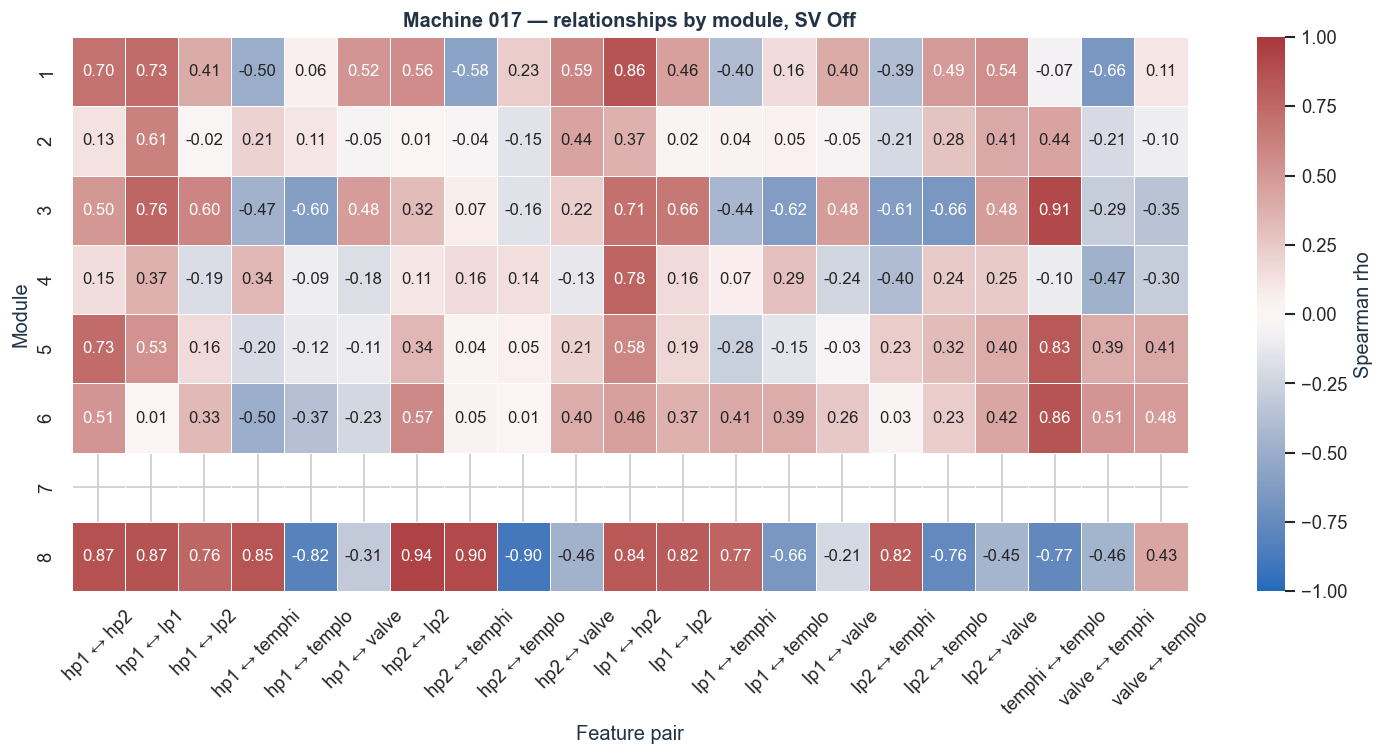

### Interactive relationship heatmap

interactive(children=(Dropdown(description='Machine', options=('017', '022', '024', '029', '041', '056', '057'…

In [10]:
def pair_name(row):
    return f"{row['feature_x']} ↔ {row['feature_y']}"

correlations["pair"] = correlations.apply(pair_name, axis=1)

def plot_machine_correlations(machine="017", sv="Off", save=False):
    part = correlations[(correlations["machine_number"] == machine) & (correlations["sv"] == sv)].copy()
    heat = part.pivot(index="module", columns="pair", values="spearman_rho").reindex(index=range(1, 9))
    fig, ax = plt.subplots(figsize=(15, 6))
    sns.heatmap(
        heat, cmap="vlag", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
        linewidths=.4, cbar_kws={"label": "Spearman rho"}, ax=ax,
    )
    ax.set_title(f"Machine {machine} — relationships by module, SV {sv}")
    ax.set_xlabel("Feature pair")
    ax.set_ylabel("Module")
    ax.tick_params(axis="x", rotation=45)
    if save:
        savefig(f"06_machine_{machine}_correlations_{sv.lower()}.png")
    plt.show()

plot_machine_correlations("017", "Off", save=True)

if widgets is not None:
    display(Markdown("### Interactive relationship heatmap"))
    widgets.interact(
        plot_machine_correlations,
        machine=widgets.Dropdown(options=machines, value=machines[0], description="Machine"),
        sv=widgets.Dropdown(options=["Off", "On"], value="Off", description="SV"),
        save=widgets.fixed(False),
    )

ค่าใกล้ `+1` หมายถึงเพิ่ม/ลดไปในทิศเดียวกัน ค่าใกล้ `-1` หมายถึงสวนทาง และค่าใกล้ `0` หมายถึงไม่มีความสัมพันธ์แบบอันดับที่ชัดเจนใน state นั้น การเห็น correlation สูงยังไม่เพียงพอจะบอกว่า feature หนึ่งเป็นสาเหตุของอีก feature

## 10. Machine × module drill-down — timeline, distribution และ scatter

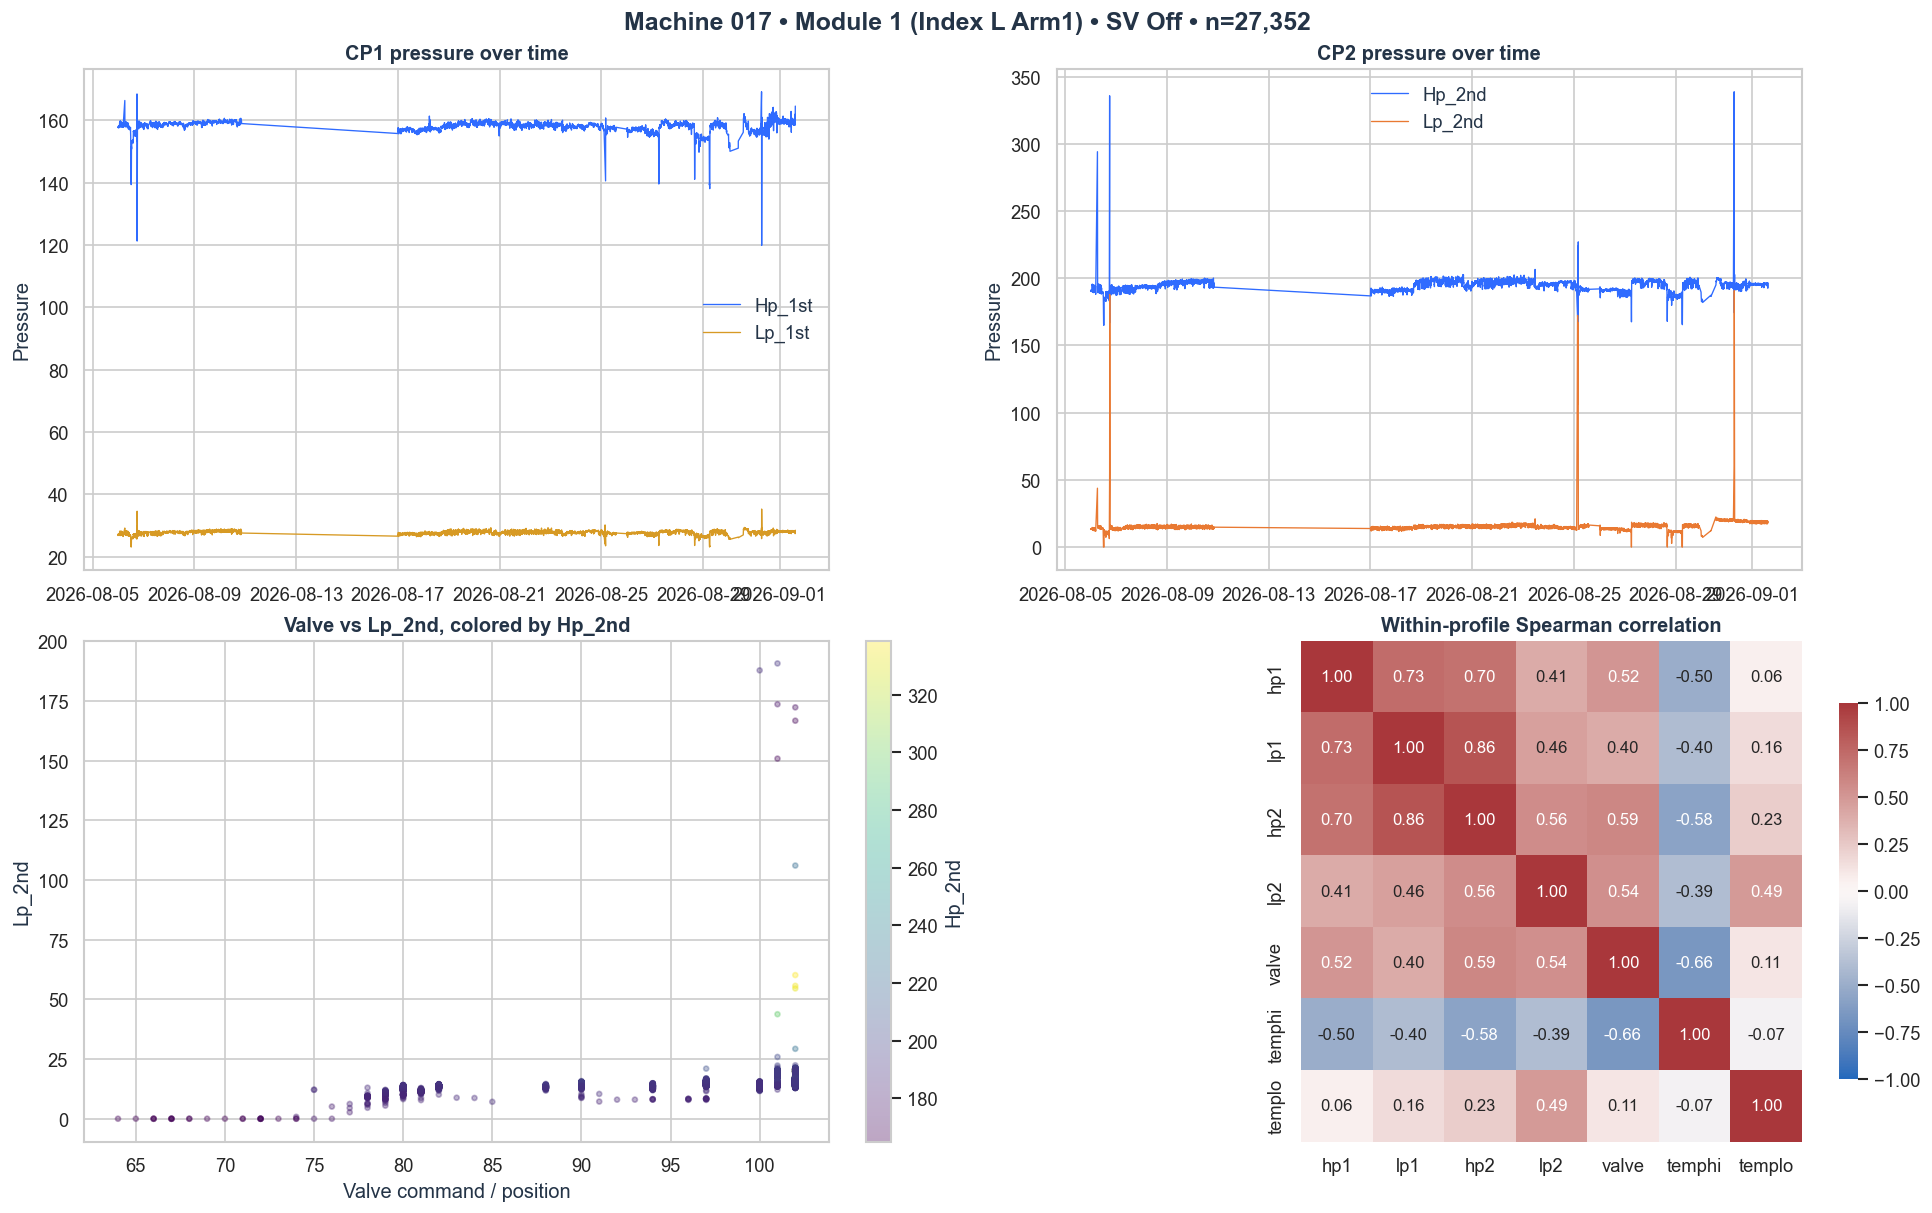

### Interactive machine × module drill-down

interactive(children=(Dropdown(description='Machine', options=('017', '022', '024', '029', '041', '056', '057'…

In [11]:
detail_columns = ["minute", "hp1", "lp1", "hp2", "lp2", "valve", "temphi", "templo", "sv"]

def get_detail(machine, module, sv):
    return (
        minute.filter(
            (pl.col("machine_number") == machine) &
            (pl.col("module") == int(module)) &
            pl.col("baseline_eligible") &
            (pl.col("sv") == sv)
        )
        .select([c for c in detail_columns if c in minute.columns])
        .sort("minute")
        .to_pandas()
    )

def plot_machine_module_detail(machine="017", module=1, sv="Off", max_points=8000, save=False):
    p = get_detail(machine, module, sv)
    if p.empty:
        display(Markdown(f"ไม่มี baseline-eligible rows สำหรับ Machine {machine}, Module {module}, SV {sv}"))
        return
    if len(p) > max_points:
        sample_idx = np.linspace(0, len(p) - 1, max_points).astype(int)
        s = p.iloc[sample_idx].copy()
    else:
        s = p.copy()

    fig, axes = plt.subplots(2, 2, figsize=(16, 10), constrained_layout=True)
    axes[0, 0].plot(s["minute"], s["hp1"], label="Hp_1st", color=PALETTE["blue"], lw=.8)
    axes[0, 0].plot(s["minute"], s["lp1"], label="Lp_1st", color=PALETTE["gold"], lw=.8)
    axes[0, 0].set_title("CP1 pressure over time")
    axes[0, 0].set_ylabel("Pressure")
    axes[0, 0].legend(frameon=False)

    axes[0, 1].plot(s["minute"], s["hp2"], label="Hp_2nd", color=PALETTE["blue"], lw=.8)
    axes[0, 1].plot(s["minute"], s["lp2"], label="Lp_2nd", color=PALETTE["orange"], lw=.8)
    axes[0, 1].set_title("CP2 pressure over time")
    axes[0, 1].set_ylabel("Pressure")
    axes[0, 1].legend(frameon=False)

    sc = axes[1, 0].scatter(s["valve"], s["lp2"], c=s["hp2"], s=9, alpha=.35,
                            cmap="viridis", rasterized=True)
    axes[1, 0].set_title("Valve vs Lp_2nd, colored by Hp_2nd")
    axes[1, 0].set_xlabel("Valve command / position")
    axes[1, 0].set_ylabel("Lp_2nd")
    fig.colorbar(sc, ax=axes[1, 0], label="Hp_2nd")

    corr_cols = ["hp1", "lp1", "hp2", "lp2", "valve", "temphi", "templo"]
    corr = p[corr_cols].corr(method="spearman")
    sns.heatmap(corr, ax=axes[1, 1], cmap="vlag", center=0, vmin=-1, vmax=1,
                annot=True, fmt=".2f", square=True, cbar_kws={"shrink": .75})
    axes[1, 1].set_title("Within-profile Spearman correlation")

    fig.suptitle(
        f"Machine {machine} • Module {module} ({module_names[int(module)]}) • SV {sv} • n={len(p):,}",
        fontsize=15, fontweight="bold",
    )
    if save:
        savefig(f"07_detail_{machine}_m{module}_{sv.lower()}.png")
    plt.show()

plot_machine_module_detail("017", 1, "Off", save=True)

if widgets is not None:
    display(Markdown("### Interactive machine × module drill-down"))
    widgets.interact(
        plot_machine_module_detail,
        machine=widgets.Dropdown(options=machines, value=machines[0], description="Machine"),
        module=widgets.Dropdown(options=[(f"{i}: {module_names[i]}", i) for i in range(1, 9)], value=1, description="Module"),
        sv=widgets.Dropdown(options=["Off", "On"], value="Off", description="SV"),
        max_points=widgets.fixed(8000),
        save=widgets.fixed(False),
    )

## 11. Daily baseline trends — ดู drift ของแต่ละ module

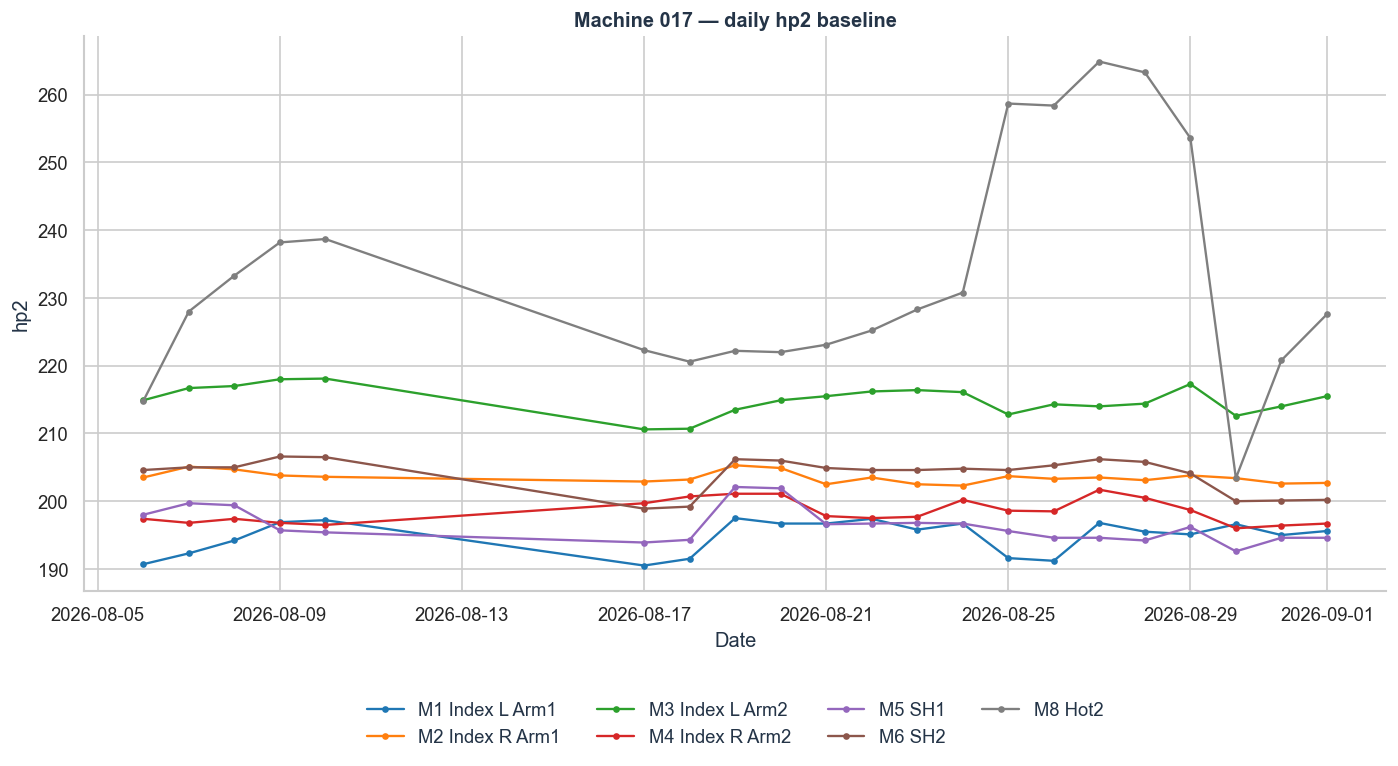

### Interactive daily trend

interactive(children=(Dropdown(description='Machine', options=('017', '022', '024', '029', '041', '056', '057'…

In [12]:
def plot_daily_trend(machine="017", metric="hp2_median", save=False):
    p = daily[daily["machine_number"] == machine].copy()
    fig, ax = plt.subplots(figsize=(14, 6))
    colors = sns.color_palette("tab10", 8)
    for module in range(1, 9):
        q = p[p["module"] == module].sort_values("date")
        if not q.empty:
            ax.plot(q["date"], q[metric], marker="o", ms=3, lw=1.4,
                    label=f"M{module} {module_names[module]}", color=colors[module - 1])
    ax.set_title(f"Machine {machine} — daily {metric.replace('_median', '')} baseline")
    ax.set_xlabel("Date")
    ax.set_ylabel(metric.replace("_median", ""))
    ax.legend(ncol=4, bbox_to_anchor=(0.5, -0.17), loc="upper center", frameon=False)
    sns.despine()
    if save:
        savefig(f"08_daily_{machine}_{metric}.png")
    plt.show()

plot_daily_trend("017", "hp2_median", save=True)

if widgets is not None:
    display(Markdown("### Interactive daily trend"))
    widgets.interact(
        plot_daily_trend,
        machine=widgets.Dropdown(options=machines, value=machines[0], description="Machine"),
        metric=widgets.Dropdown(
            options=[("Hp_2nd", "hp2_median"), ("Lp_2nd", "lp2_median"), ("Valve", "valve_median")],
            value="hp2_median", description="Metric",
        ),
        save=widgets.fixed(False),
    )

## 12. Lag response — Valve เปลี่ยนแล้ว pressure/temperature ตามหรือไม่

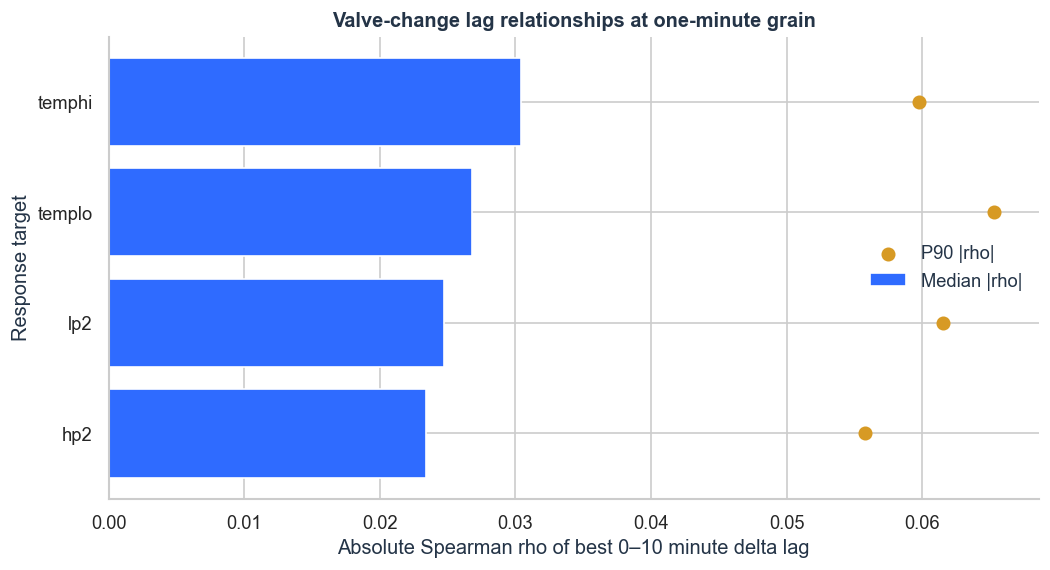

In [13]:
delta_lags = best_lags[best_lags["relationship_type"] == "delta"].copy()
lag_summary = (
    delta_lags.groupby("target")
    .agg(median_abs_rho=("abs_rho", "median"), p90_abs_rho=("abs_rho", lambda x: x.quantile(.9)),
         profiles=("abs_rho", "size"))
    .reset_index()
    .sort_values("median_abs_rho")
)

fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(lag_summary))
ax.barh(y, lag_summary["median_abs_rho"], color=PALETTE["blue"], label="Median |rho|")
ax.scatter(lag_summary["p90_abs_rho"], y, color=PALETTE["gold"], s=55, label="P90 |rho|")
ax.set_yticks(y, lag_summary["target"])
ax.set_xlabel("Absolute Spearman rho of best 0–10 minute delta lag")
ax.set_ylabel("Response target")
ax.set_title("Valve-change lag relationships at one-minute grain")
ax.legend(frameon=False)
sns.despine()
savefig("09_lag_response_summary.png")
plt.show()

**ข้อสรุป:** ความสัมพันธ์ของ `ΔValve → Δpressure/temperature` ที่ aggregate ระดับ 1 นาทีค่อนข้างอ่อน จึงยังไม่ควรสรุปว่า valve ไม่มีผล ทางวิเคราะห์ถัดไปควรใช้ event windows จากข้อมูล 1 วินาทีรอบ `ChangeValve` เพื่อวัด response delay, gain และ settling โดยตรง

## 13. Relative features — ทำให้ model เปรียบเทียบเครื่องต่างกันได้

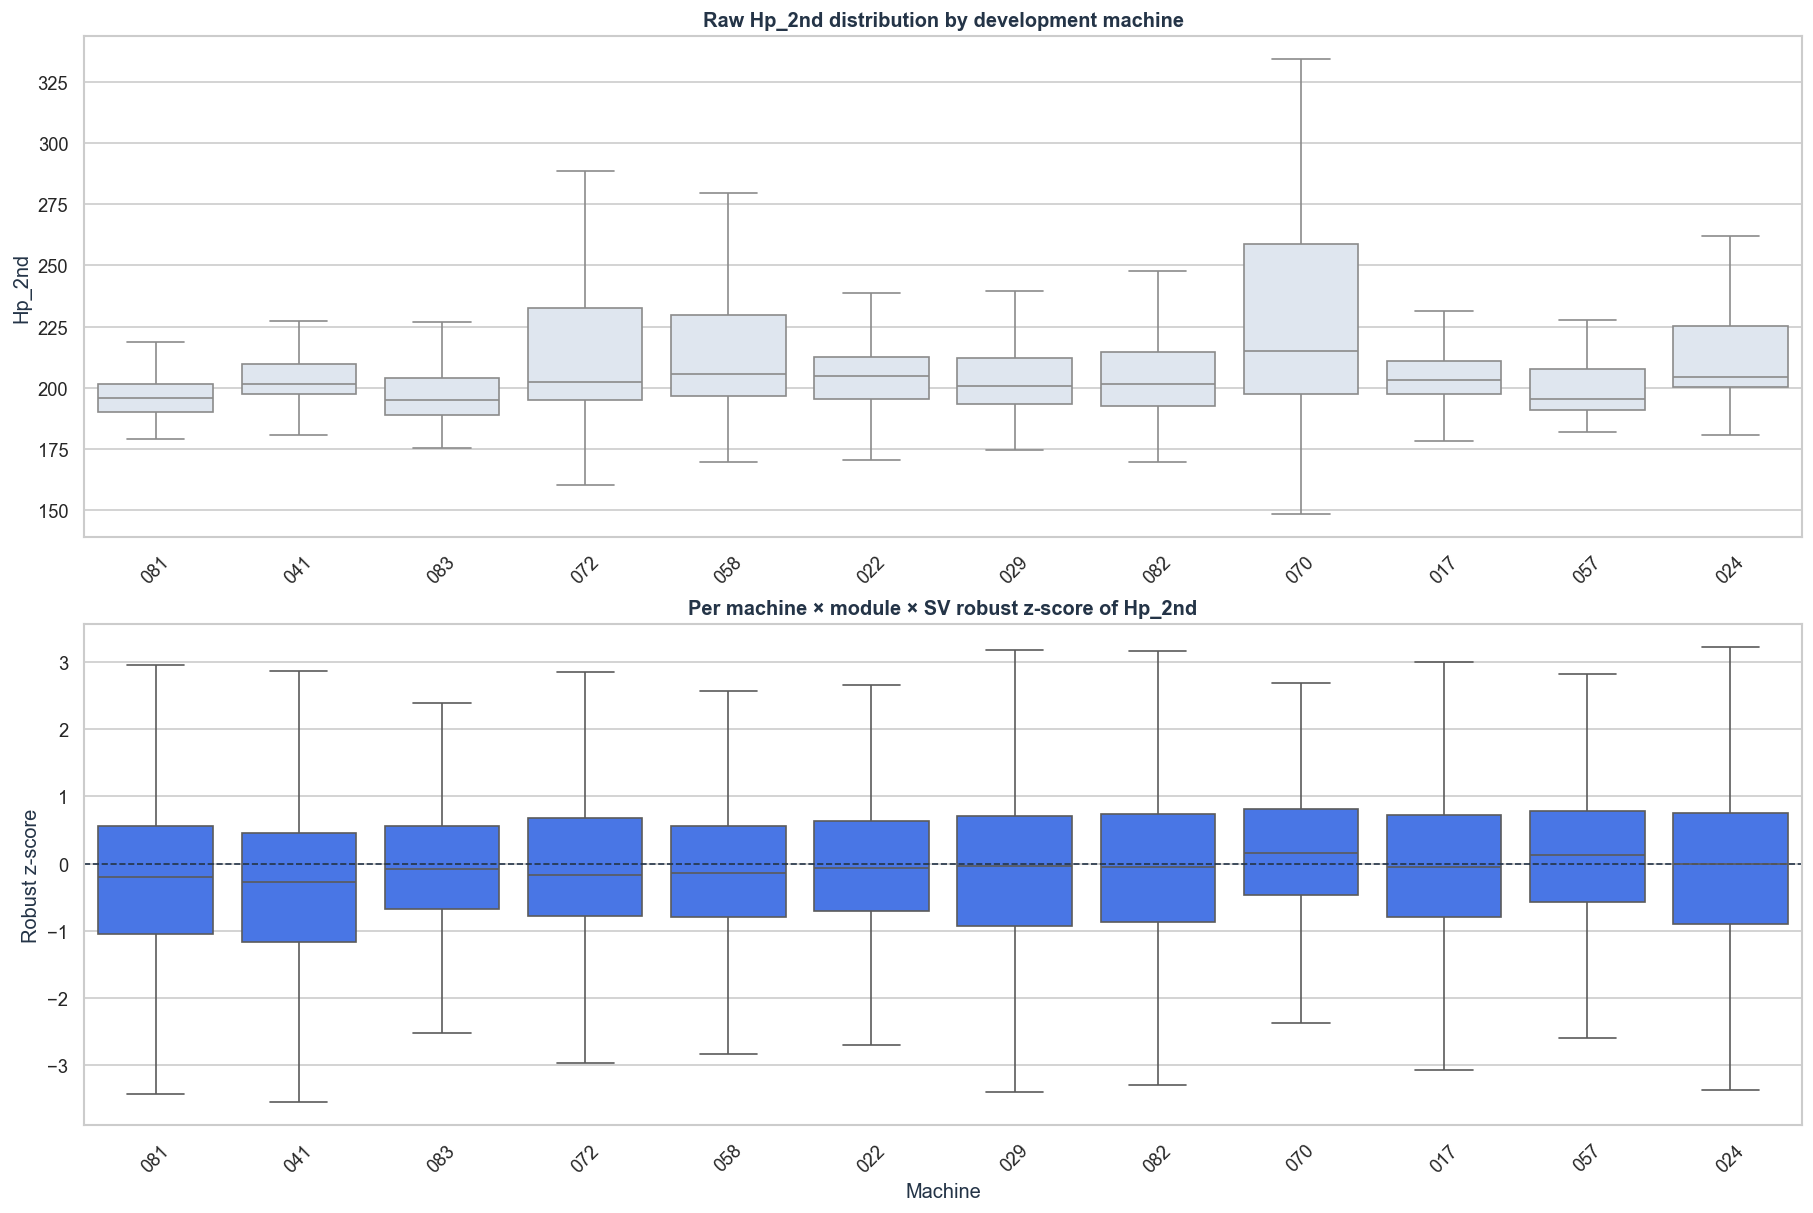

In [14]:
feature_file = ML_OUT / "ml_relative_features.parquet"
relative_rows = (
    pl.scan_parquet(feature_file)
    .select(["machine_number", "rz_hp2"])
    .filter(pl.col("machine_number").is_in(development_machines))
    .collect()
)
relative_sample = (
    relative_rows.sample(n=min(300000, relative_rows.height), seed=42)
    .to_pandas()
)
raw_rows = minute.filter(
    pl.col("baseline_eligible") & pl.col("machine_number").is_in(development_machines)
).select(["machine_number", "hp2"])
raw_sample = raw_rows.sample(n=min(300000, raw_rows.height), seed=42).to_pandas()

fig, axes = plt.subplots(2, 1, figsize=(15, 10), constrained_layout=True)
sns.boxplot(data=raw_sample, x="machine_number", y="hp2", color=PALETTE["light"],
            showfliers=False, ax=axes[0])
axes[0].set_title("Raw Hp_2nd distribution by development machine")
axes[0].set_xlabel("")
axes[0].set_ylabel("Hp_2nd")
sns.boxplot(data=relative_sample, x="machine_number", y="rz_hp2", color=PALETTE["blue"],
            showfliers=False, ax=axes[1])
axes[1].axhline(0, color=PALETTE["ink"], lw=1, ls="--")
axes[1].set_title("Per machine × module × SV robust z-score of Hp_2nd")
axes[1].set_xlabel("Machine")
axes[1].set_ylabel("Robust z-score")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
savefig("10_relative_feature_normalization.png")
plt.show()

กราฟบนคือค่าจริงที่ baseline แตกต่างระหว่างเครื่อง ส่วนกราฟล่างเปลี่ยนเป็นระยะห่างจาก baseline ของเครื่อง–module–SV นั้นเอง จึงเหมาะกับ shared model มากกว่าใช้ pressure absolute ร่วมกันทั้ง fleet

## 14. ML validation — time split, leave-one-machine-out และ external test

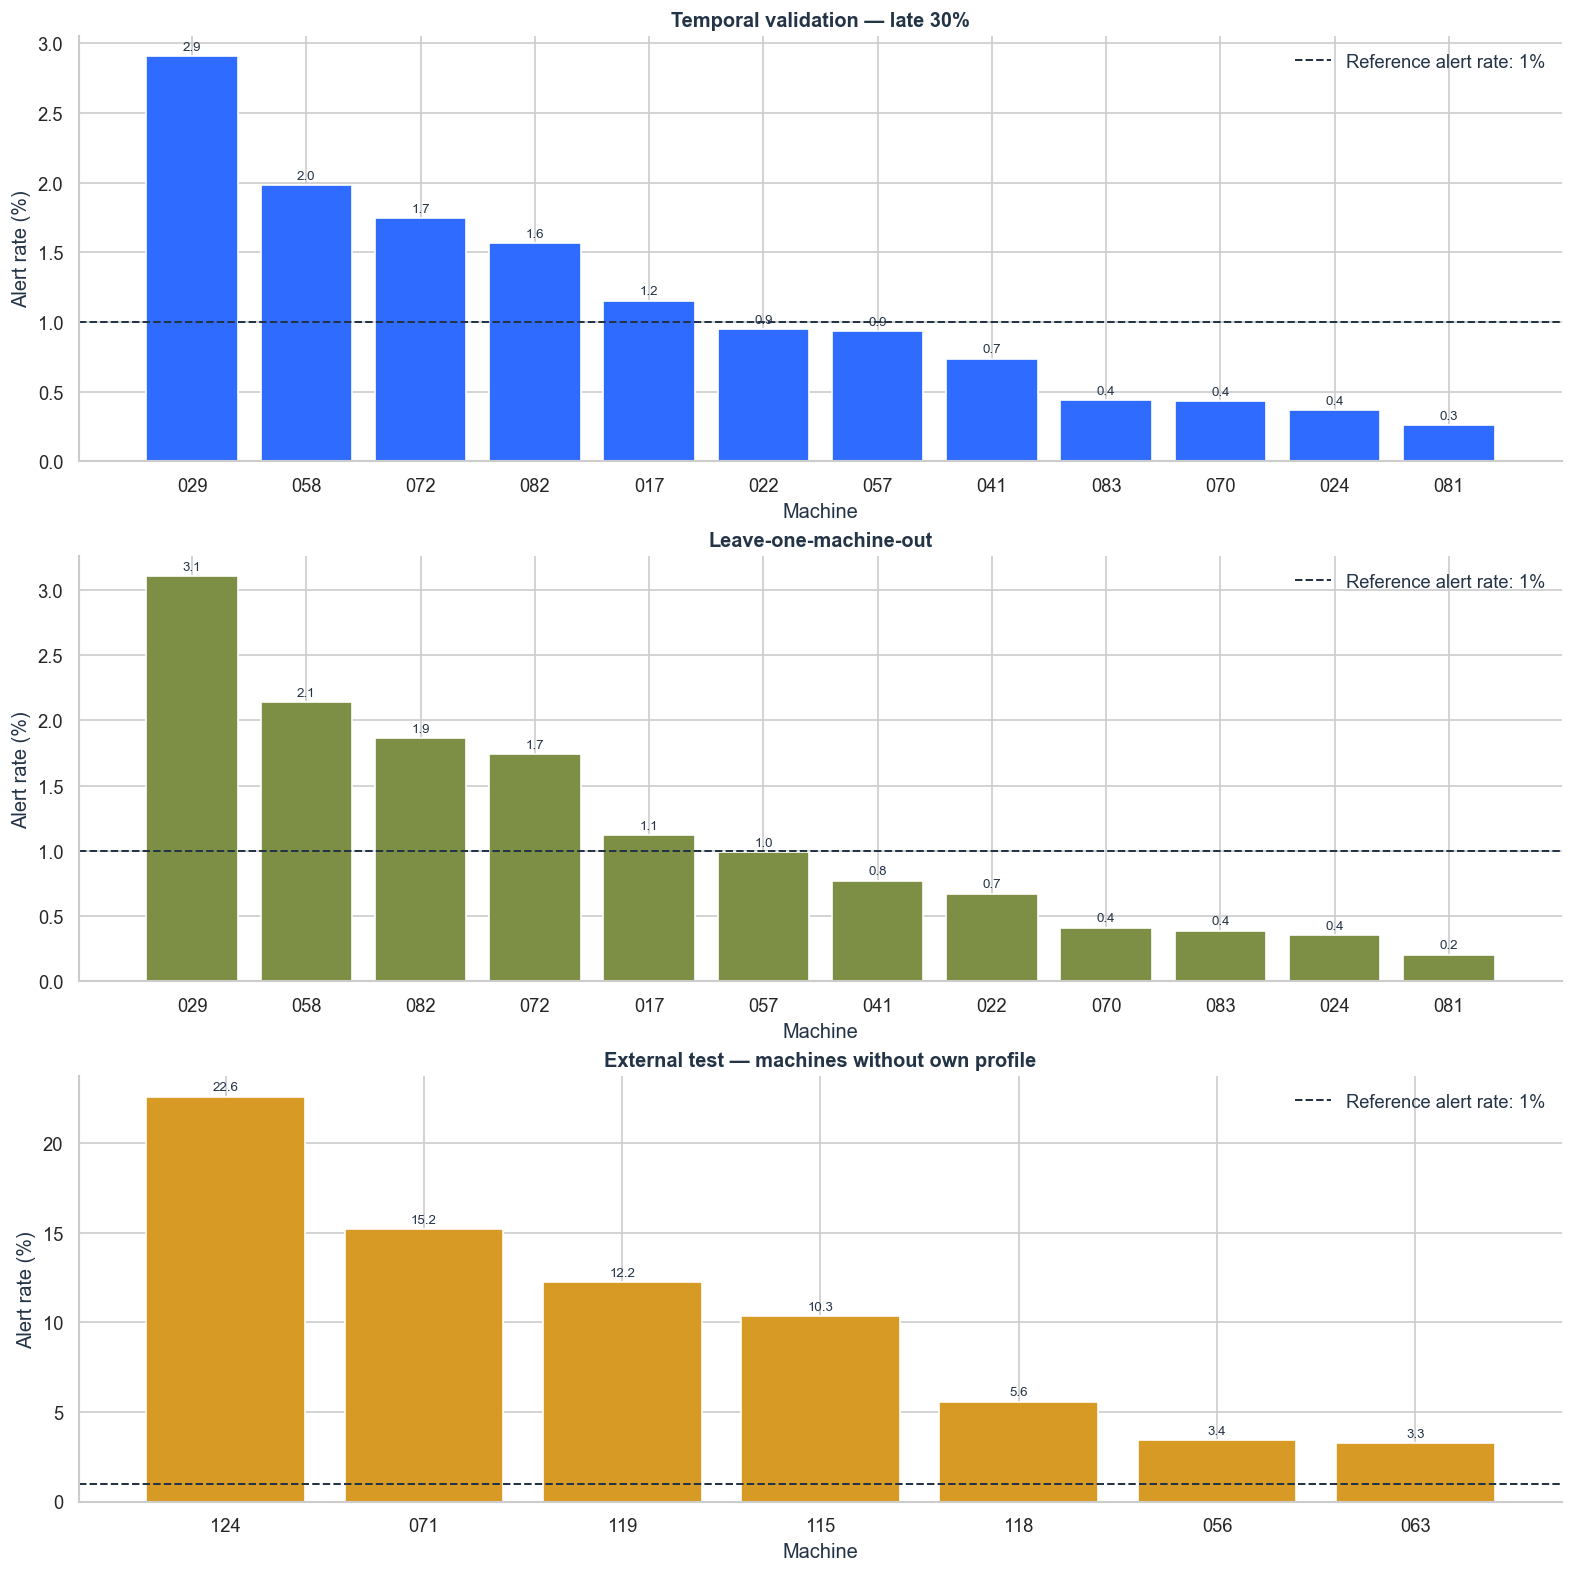

- Temporal median alert rate: **0.94%**  
- LOMO median alert rate: **0.88%**  
- External-test median alert rate: **10.34%**

In [15]:
temporal_plot = temporal.rename(columns={"machine_number": "machine"})[["machine", "alert_rate_pct"]].copy()
temporal_plot["validation"] = "Temporal (late 30%)"
lomo_plot = lomo.rename(columns={"held_out_machine": "machine"})[["machine", "alert_rate_pct"]].copy()
lomo_plot["validation"] = "LOMO"
external_plot = external.rename(columns={"machine_number": "machine"})[["machine", "alert_rate_pct"]].copy()
external_plot["validation"] = "External / cold start"

fig, axes = plt.subplots(3, 1, figsize=(13, 13), constrained_layout=True)
panels = [
    (temporal_plot, "Temporal validation — late 30%", PALETTE["blue"]),
    (lomo_plot, "Leave-one-machine-out", PALETTE["olive"]),
    (external_plot, "External test — machines without own profile", PALETTE["gold"]),
]
for ax, (p, title, color) in zip(axes, panels):
    p = p.sort_values("alert_rate_pct", ascending=False)
    bars = ax.bar(p["machine"], p["alert_rate_pct"], color=color)
    ax.axhline(1.0, color=PALETTE["ink"], ls="--", lw=1.2, label="Reference alert rate: 1%")
    ax.set_title(title)
    ax.set_ylabel("Alert rate (%)")
    ax.set_xlabel("Machine")
    ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8)
    ax.legend(frameon=False, loc="upper right")
    sns.despine(ax=ax)
savefig("11_ml_validation.png")
plt.show()

display(Markdown(
    f"- Temporal median alert rate: **{ml_summary['temporal_validation_median_alert_pct']:.2f}%**  \n"
    f"- LOMO median alert rate: **{ml_summary['lomo_median_alert_pct']:.2f}%**  \n"
    f"- External-test median alert rate: **{ml_summary['external_test_median_alert_pct']:.2f}%**"
))

**วิธีอ่าน:** Temporal และ LOMO ใกล้ reference 1% แสดงว่า shared relative model ถ่ายโอนระหว่างเครื่องที่มี calibration ของตัวเองได้พอสมควร แต่ external test สูงกว่าอย่างชัดเจน เพราะต้องใช้ fleet cold-start profile แทน baseline ของเครื่องเอง ตัวเลขสูงนี้จึงยังไม่ใช่หลักฐานว่า 7 เครื่องเสีย

## 15. Takeaways

In [16]:
takeaways = f'''
### สรุปแบบเข้าใจง่าย

1. **Baseline ไม่เท่ากันจริง** — ความต่างระหว่างเครื่องมีค่ากลางประมาณ **{analysis_summary['median_between_to_within_ratio']:.2f} เท่า** ของความผันผวนปกติภายในเครื่อง จึงไม่ควรใช้ threshold เดียวทั้ง fleet
2. ต้องสร้าง calibration แยก **machine × module × SV** และใช้ robust z-score / relative features เมื่อต้องการ shared ML model
3. มี **{ml_summary['development_machine_count']} เครื่อง** ที่ข้อมูลพอสำหรับ temporal + LOMO และ **{ml_summary['external_test_machine_count']} เครื่อง** ที่ควรอยู่ใน external test / shadow mode จนกว่าจะมี baseline ของตัวเอง
4. Pressure, valve และ temperature มีความสัมพันธ์ต่างกันตามเครื่องและ module; heatmap และ drill-down ด้านบนใช้ตรวจได้ทีละ profile
5. Lag response ที่ระดับ 1 นาทีอ่อน จึงควรทำ event analysis จากข้อมูล 1 วินาทีรอบ `ChangeValve` เป็นงานถัดไป
6. โมเดลปัจจุบันตรวจ **ความแตกต่างจากพฤติกรรมอ้างอิง** เท่านั้น ยังไม่มี maintenance label พอจะยืนยัน leak, undercharge หรือ failure type

### สิ่งที่ควรเก็บเพิ่มก่อนใช้แจ้งซ่อมจริง

- recipe / mode / phase, target และ actual controlled temperature
- facility-water inlet/outlet temperature และ flow/pressure
- alarm/event code, maintenance timestamp และผลตรวจยืนยันของช่าง
- firmware/configuration และ sensor calibration history
'''
display(Markdown(takeaways))


### สรุปแบบเข้าใจง่าย

1. **Baseline ไม่เท่ากันจริง** — ความต่างระหว่างเครื่องมีค่ากลางประมาณ **4.64 เท่า** ของความผันผวนปกติภายในเครื่อง จึงไม่ควรใช้ threshold เดียวทั้ง fleet
2. ต้องสร้าง calibration แยก **machine × module × SV** และใช้ robust z-score / relative features เมื่อต้องการ shared ML model
3. มี **12 เครื่อง** ที่ข้อมูลพอสำหรับ temporal + LOMO และ **7 เครื่อง** ที่ควรอยู่ใน external test / shadow mode จนกว่าจะมี baseline ของตัวเอง
4. Pressure, valve และ temperature มีความสัมพันธ์ต่างกันตามเครื่องและ module; heatmap และ drill-down ด้านบนใช้ตรวจได้ทีละ profile
5. Lag response ที่ระดับ 1 นาทีอ่อน จึงควรทำ event analysis จากข้อมูล 1 วินาทีรอบ `ChangeValve` เป็นงานถัดไป
6. โมเดลปัจจุบันตรวจ **ความแตกต่างจากพฤติกรรมอ้างอิง** เท่านั้น ยังไม่มี maintenance label พอจะยืนยัน leak, undercharge หรือ failure type

### สิ่งที่ควรเก็บเพิ่มก่อนใช้แจ้งซ่อมจริง

- recipe / mode / phase, target และ actual controlled temperature
- facility-water inlet/outlet temperature และ flow/pressure
- alarm/event code, maintenance timestamp และผลตรวจยืนยันของช่าง
- firmware/configuration และ sensor calibration history


## 16. Exported figures

กราฟหลักทั้งหมดถูกบันทึกไว้ใน `notebooks/outputs/ht9046mx_visual_story/figures/` เมื่อรัน notebook จบ สามารถนำ PNG ไปใช้ในรายงานหรือ presentation ต่อได้

In [17]:
exported = sorted(FIG_OUT.glob("*.png"))
pd.DataFrame({"figure": [p.name for p in exported], "path": [str(p) for p in exported]})

,figure,path
0,01_machine_coverage.png,C:\Users\Book\OneDrive\Documents\ChatGPT\OPERA...
1,02_state_composition.png,C:\Users\Book\OneDrive\Documents\ChatGPT\OPERA...
2,03_baseline_comparability.png,C:\Users\Book\OneDrive\Documents\ChatGPT\OPERA...
3,04_baseline_map_hp2_off.png,C:\Users\Book\OneDrive\Documents\ChatGPT\OPERA...
4,05_machine_017_hp2_baseline_interval.png,C:\Users\Book\OneDrive\Documents\ChatGPT\OPERA...
5,06_machine_017_correlations_off.png,C:\Users\Book\OneDrive\Documents\ChatGPT\OPERA...
6,06a_normal_vs_relationship_017_m1_off.png,C:\Users\Book\OneDrive\Documents\ChatGPT\OPERA...
7,07_detail_017_m1_off.png,C:\Users\Book\OneDrive\Documents\ChatGPT\OPERA...
8,08_daily_017_hp2_median.png,C:\Users\Book\OneDrive\Documents\ChatGPT\OPERA...
9,09_lag_response_summary.png,C:\Users\Book\OneDrive\Documents\ChatGPT\OPERA...
